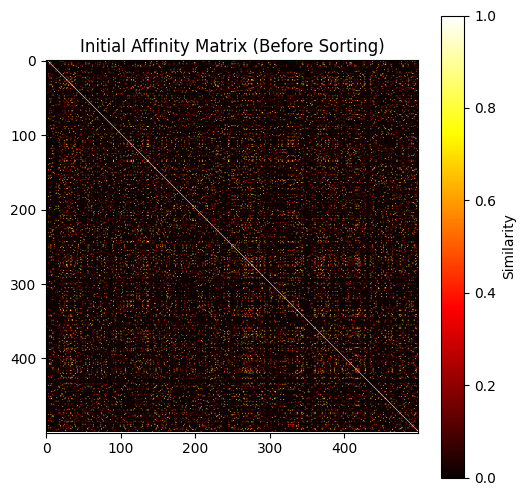

<ipython-input-27-b663a405d928>:36: RuntimeWarning: invalid value encountered in divide
  mu[g] = np.sum(probabilities[:, g][:, np.newaxis] * eigenvectors, axis=0) / probabilities[:, g].sum()


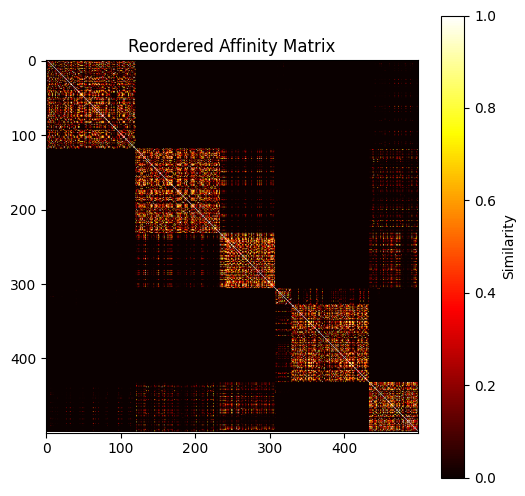

<ipython-input-27-b663a405d928>:97: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(data[:, 0], data[:, 1], s=50, cmap="viridis")


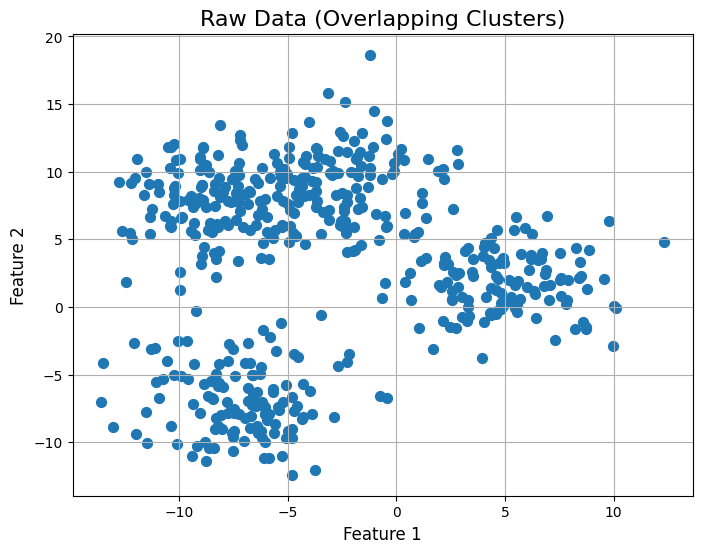

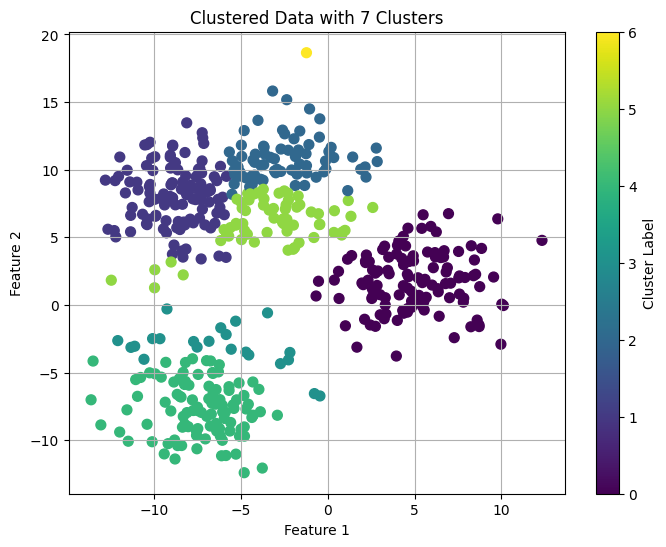

Silhouette Score: 0.40


In [27]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from scipy.linalg import eigh
from sklearn.datasets import make_blobs

def construct_gaussian_affinity_matrix(data, sigma=1.0):
    n_samples = data.shape[0]
    affinity_matrix = np.zeros((n_samples, n_samples))
    for i in range(n_samples):
        for j in range(n_samples):
            distance = np.linalg.norm(data[i] - data[j])
            affinity_matrix[i, j] = np.exp(-distance**2 / (2 * sigma**2))
    return affinity_matrix

def normalize_affinity_matrix(affinity_matrix):
    D = np.diag(np.sum(affinity_matrix, axis=1))
    D_inv_sqrt = np.linalg.inv(np.sqrt(D))
    normalized_affinity = D_inv_sqrt @ affinity_matrix @ D_inv_sqrt
    return normalized_affinity

def compute_relevance(eigenvectors, max_iter=100):
    n_samples, n_eigenvectors = eigenvectors.shape
    R_ek = np.full(n_eigenvectors, 0.5)
    mu = np.random.rand(2, n_eigenvectors)
    sigma = np.random.rand(2, n_eigenvectors)
    weights = np.full(2, 0.5)
    for iteration in range(max_iter):
        probabilities = np.zeros((n_samples, 2))
        for g in range(2):
            probabilities[:, g] = weights[g] * np.exp(-0.5 * np.sum(((eigenvectors - mu[g]) / sigma[g])**2, axis=1))
        probabilities /= probabilities.sum(axis=1, keepdims=True)
        for g in range(2):
            weights[g] = probabilities[:, g].mean()
            mu[g] = np.sum(probabilities[:, g][:, np.newaxis] * eigenvectors, axis=0) / probabilities[:, g].sum()
            sigma[g] = np.sqrt(
                np.sum(probabilities[:, g][:, np.newaxis] * (eigenvectors - mu[g])**2, axis=0) /
                probabilities[:, g].sum()
            )
    return R_ek

def weighted_eigenvectors(eigenvectors, relevances):
    weighted_vectors = eigenvectors * relevances
    return weighted_vectors

def extract_and_evaluate_eigenvectors_with_weights(affinity_matrix, num_eigenvectors=5):
    eigenvalues, eigenvectors = eigh(affinity_matrix)
    indices = np.argsort(eigenvalues)[-num_eigenvectors:]
    eigenvectors = eigenvectors[:, indices]
    relevances = compute_relevance(eigenvectors)
    weighted_data = weighted_eigenvectors(eigenvectors, relevances)
    return weighted_data, relevances

def cluster_with_gmm(data, max_clusters=10):
    best_bic = np.inf
    best_gmm = None
    for num_clusters in range(2, max_clusters + 1):
        gmm = GaussianMixture(n_components=num_clusters, covariance_type='full', random_state=42)
        gmm.fit(data)
        bic = gmm.bic(data)
        if bic < best_bic:
            best_bic = bic
            best_gmm = gmm
    return best_gmm, best_gmm.n_components

def spectral_clustering_algorithm_with_weights(data, sigma=1.5, num_eigenvectors=5):
    affinity_matrix = construct_gaussian_affinity_matrix(data, sigma=sigma)
    plt.figure(figsize=(6, 6))
    plt.imshow(affinity_matrix, cmap="hot")
    plt.title("Initial Affinity Matrix (Before Sorting)")
    plt.colorbar(label="Similarity")
    plt.show()

    normalized_affinity = normalize_affinity_matrix(affinity_matrix)
    weighted_data, relevances = extract_and_evaluate_eigenvectors_with_weights(
        normalized_affinity, num_eigenvectors
    )
    gmm_model, optimal_clusters = cluster_with_gmm(weighted_data)
    cluster_labels = gmm_model.predict(weighted_data)
    sorted_indices = np.argsort(cluster_labels)
    reordered_matrix = affinity_matrix[np.ix_(sorted_indices, sorted_indices)]
    plt.figure(figsize=(6, 6))
    plt.imshow(reordered_matrix, cmap="hot")
    plt.title("Reordered Affinity Matrix")
    plt.colorbar(label="Similarity")
    plt.show()
    return cluster_labels, optimal_clusters, relevances

if __name__ == "__main__":
    data, _ = make_blobs(n_samples=500, centers=4, cluster_std=2.5, random_state=42)

    cluster_labels, optimal_clusters, relevances = spectral_clustering_algorithm_with_weights(
        data, sigma=1.5, num_eigenvectors=10
    )
    plt.figure(figsize=(8, 6))
    plt.scatter(data[:, 0], data[:, 1], s=50, cmap="viridis")
    plt.title("Raw Data (Overlapping Clusters)", fontsize=16)
    plt.xlabel("Feature 1", fontsize=12)
    plt.ylabel("Feature 2", fontsize=12)
    plt.grid()
    plt.show()

    plt.figure(figsize=(8, 6))
    plt.scatter(data[:, 0], data[:, 1], c=cluster_labels, cmap="viridis", s=50)
    plt.title(f"Clustered Data with {optimal_clusters} Clusters")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.colorbar(label="Cluster Label")
    plt.grid()
    plt.show()

    silhouette_avg = silhouette_score(data, cluster_labels)
    print(f"Silhouette Score: {silhouette_avg:.2f}")


<ipython-input-24-476a33de18f6>:36: RuntimeWarning: invalid value encountered in divide
  mu[g] = np.sum(probabilities[:, g][:, np.newaxis] * eigenvectors, axis=0) / probabilities[:, g].sum()


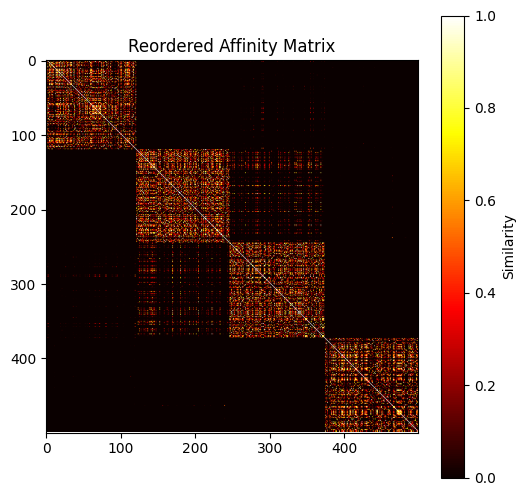

<ipython-input-24-476a33de18f6>:84: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(data[:, 0], data[:, 1], s=50, cmap="viridis")


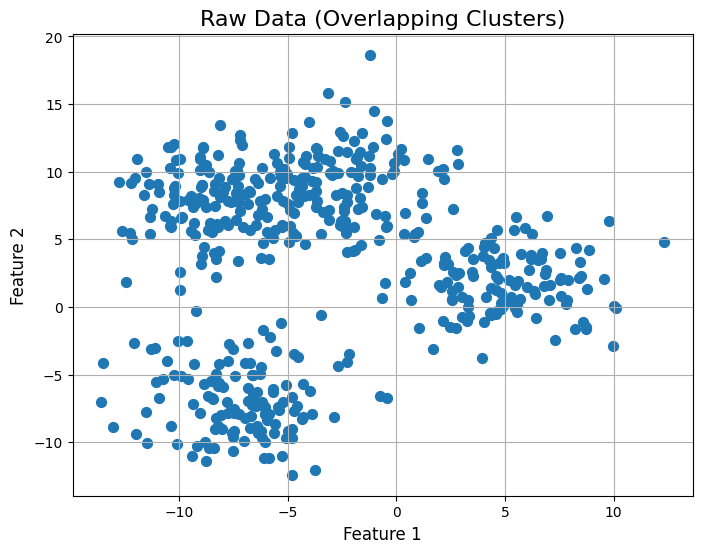

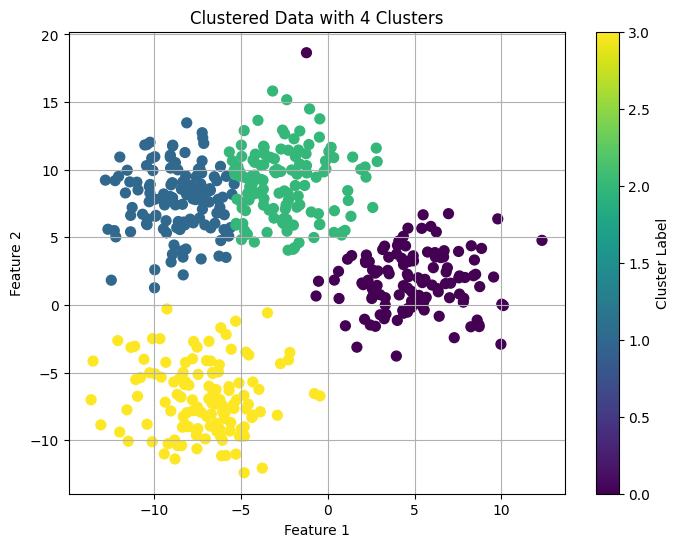

Silhouette Score: 0.52


In [24]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from scipy.linalg import eigh
from sklearn.datasets import make_blobs

def construct_gaussian_affinity_matrix(data, sigma=1.0):
    n_samples = data.shape[0]
    affinity_matrix = np.zeros((n_samples, n_samples))
    for i in range(n_samples):
        for j in range(n_samples):
            distance = np.linalg.norm(data[i] - data[j])
            affinity_matrix[i, j] = np.exp(-distance**2 / (2 * sigma**2))
    return affinity_matrix

def normalize_affinity_matrix(affinity_matrix):
    D = np.diag(np.sum(affinity_matrix, axis=1))
    D_inv_sqrt = np.linalg.inv(np.sqrt(D))
    normalized_affinity = D_inv_sqrt @ affinity_matrix @ D_inv_sqrt
    return normalized_affinity

def compute_relevance(eigenvectors, max_iter=100):
    n_samples, n_eigenvectors = eigenvectors.shape
    R_ek = np.full(n_eigenvectors, 0.5)
    mu = np.random.rand(2, n_eigenvectors)
    sigma = np.random.rand(2, n_eigenvectors)
    weights = np.full(2, 0.5)
    for iteration in range(max_iter):
        probabilities = np.zeros((n_samples, 2))
        for g in range(2):
            probabilities[:, g] = weights[g] * np.exp(-0.5 * np.sum(((eigenvectors - mu[g]) / sigma[g])**2, axis=1))
        probabilities /= probabilities.sum(axis=1, keepdims=True)
        for g in range(2):
            weights[g] = probabilities[:, g].mean()
            mu[g] = np.sum(probabilities[:, g][:, np.newaxis] * eigenvectors, axis=0) / probabilities[:, g].sum()
            sigma[g] = np.sqrt(
                np.sum(probabilities[:, g][:, np.newaxis] * (eigenvectors - mu[g])**2, axis=0) /
                probabilities[:, g].sum()
            )
    return R_ek

def weighted_eigenvectors(eigenvectors, relevances):
    weighted_vectors = eigenvectors * relevances
    return weighted_vectors

def extract_and_evaluate_eigenvectors_with_weights(affinity_matrix, num_eigenvectors=5):
    eigenvalues, eigenvectors = eigh(affinity_matrix)
    indices = np.argsort(eigenvalues)[-num_eigenvectors:]
    eigenvectors = eigenvectors[:, indices]
    relevances = compute_relevance(eigenvectors)
    weighted_data = weighted_eigenvectors(eigenvectors, relevances)
    return weighted_data, relevances

def cluster_with_fixed_gmm(data, fixed_clusters=3):
    gmm = GaussianMixture(n_components=fixed_clusters, covariance_type='full', random_state=42)
    gmm.fit(data)
    return gmm, fixed_clusters

def spectral_clustering_algorithm_with_fixed_clusters(data, sigma=1.5, num_eigenvectors=10, fixed_clusters=3):
    affinity_matrix = construct_gaussian_affinity_matrix(data, sigma=sigma)
    normalized_affinity = normalize_affinity_matrix(affinity_matrix)
    weighted_data, relevances = extract_and_evaluate_eigenvectors_with_weights(
        normalized_affinity, num_eigenvectors
    )
    gmm_model, _ = cluster_with_fixed_gmm(weighted_data, fixed_clusters=fixed_clusters)
    cluster_labels = gmm_model.predict(weighted_data)
    sorted_indices = np.argsort(cluster_labels)
    reordered_matrix = affinity_matrix[np.ix_(sorted_indices, sorted_indices)]
    plt.figure(figsize=(6, 6))
    plt.imshow(reordered_matrix, cmap="hot")
    plt.title("Reordered Affinity Matrix")
    plt.colorbar(label="Similarity")
    plt.show()
    return cluster_labels, fixed_clusters, relevances

if __name__ == "__main__":
    data, _ = make_blobs(n_samples=500, centers=4, cluster_std=2.5, random_state=42)

    cluster_labels, fixed_clusters, relevances = spectral_clustering_algorithm_with_fixed_clusters(
        data, sigma=1.5, num_eigenvectors=10, fixed_clusters=4
    )
    plt.figure(figsize=(8, 6))
    plt.scatter(data[:, 0], data[:, 1], s=50, cmap="viridis")
    plt.title("Raw Data (Overlapping Clusters)", fontsize=16)
    plt.xlabel("Feature 1", fontsize=12)
    plt.ylabel("Feature 2", fontsize=12)
    plt.grid()
    plt.show()

    plt.figure(figsize=(8, 6))
    plt.scatter(data[:, 0], data[:, 1], c=cluster_labels, cmap="viridis", s=50)
    plt.title(f"Clustered Data with {fixed_clusters} Clusters")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.colorbar(label="Cluster Label")
    plt.grid()
    plt.show()

    silhouette_avg = silhouette_score(data, cluster_labels)
    print(f"Silhouette Score: {silhouette_avg:.2f}")


<ipython-input-28-ecea2e33e4e6>:8: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(data[:, 0], data[:, 1], s=50, cmap='viridis')


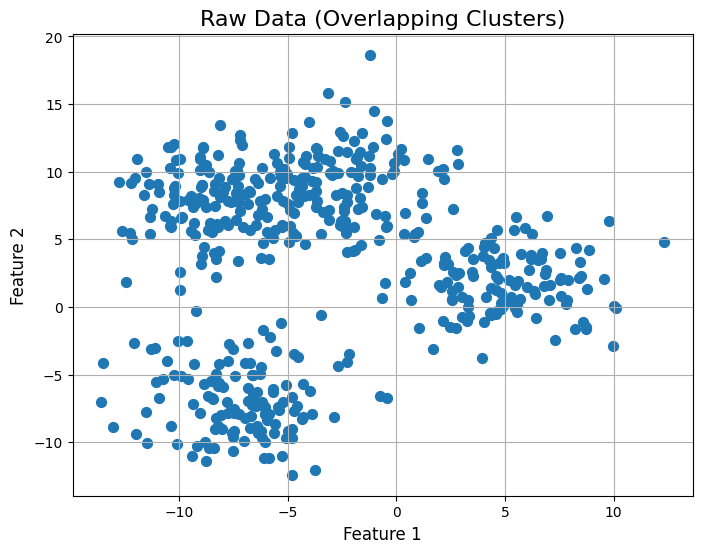

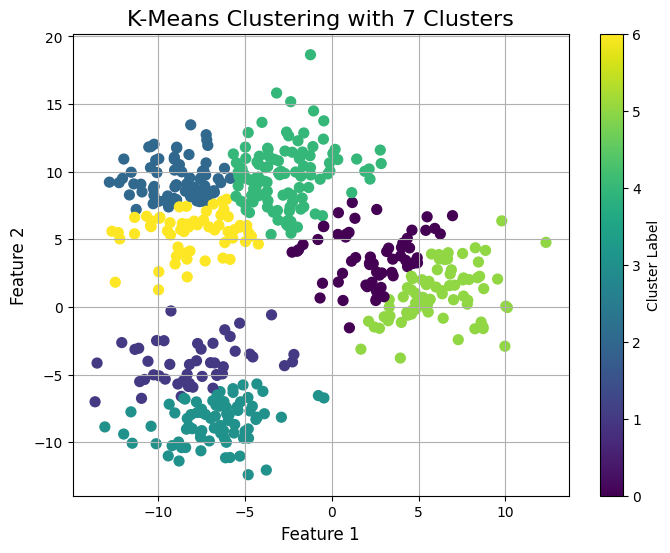

K-Means Silhouette Score: 0.35


In [28]:
from sklearn.cluster import KMeans


data, _ = make_blobs(n_samples=500, centers=4, cluster_std=2.5, random_state=42)  # Increased cluster_std


plt.figure(figsize=(8, 6))
plt.scatter(data[:, 0], data[:, 1], s=50, cmap='viridis')
plt.title("Raw Data (Overlapping Clusters)", fontsize=16)
plt.xlabel("Feature 1", fontsize=12)
plt.ylabel("Feature 2", fontsize=12)
plt.grid()
plt.show()


n_clusters = 7
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
kmeans_labels = kmeans.fit_predict(data)

plt.figure(figsize=(8, 6))
plt.scatter(data[:, 0], data[:, 1], c=kmeans_labels, cmap='viridis', s=50)
plt.title(f"K-Means Clustering with {n_clusters} Clusters", fontsize=16)
plt.xlabel("Feature 1", fontsize=12)
plt.ylabel("Feature 2", fontsize=12)
plt.colorbar(label="Cluster Label")
plt.grid()
plt.show()

kmeans_silhouette_avg = silhouette_score(data, kmeans_labels)
print(f"K-Means Silhouette Score: {kmeans_silhouette_avg:.2f}")


<ipython-input-29-1ab4b0eab960>:9: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(data[:, 0], data[:, 1], s=50, cmap='viridis')


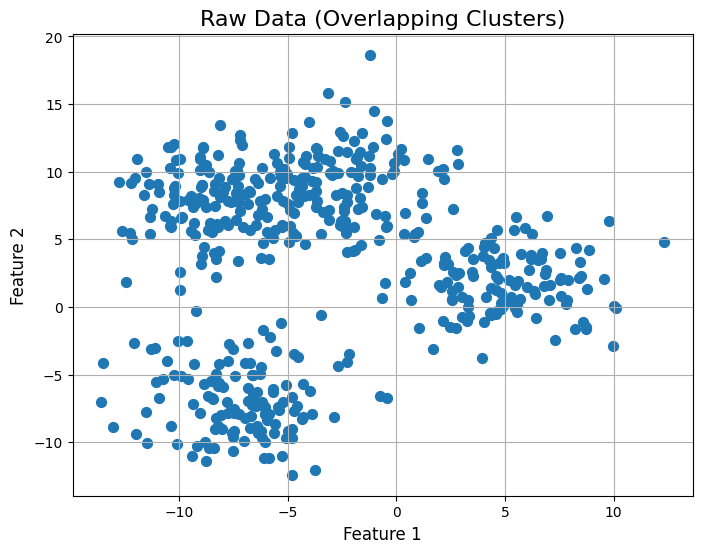

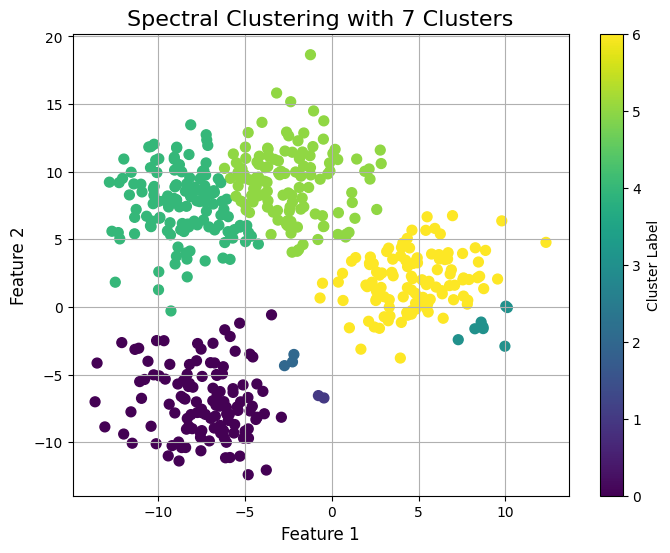

Spectral Clustering Silhouette Score: 0.35


In [29]:
from sklearn.cluster import SpectralClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

data, _ = make_blobs(n_samples=500, centers=4, cluster_std=2.5, random_state=42)

plt.figure(figsize=(8, 6))
plt.scatter(data[:, 0], data[:, 1], s=50, cmap='viridis')
plt.title("Raw Data (Overlapping Clusters)", fontsize=16)
plt.xlabel("Feature 1", fontsize=12)
plt.ylabel("Feature 2", fontsize=12)
plt.grid()
plt.show()

spectral = SpectralClustering(n_clusters=7, affinity='rbf', random_state=42)
spectral_labels = spectral.fit_predict(data)

plt.figure(figsize=(8, 6))
plt.scatter(data[:, 0], data[:, 1], c=spectral_labels, cmap='viridis', s=50)
plt.title(f"Spectral Clustering with {n_clusters} Clusters", fontsize=16)
plt.xlabel("Feature 1", fontsize=12)
plt.ylabel("Feature 2", fontsize=12)
plt.colorbar(label="Cluster Label")
plt.grid()
plt.show()

spectral_silhouette_avg = silhouette_score(data, spectral_labels)
print(f"Spectral Clustering Silhouette Score: {spectral_silhouette_avg:.2f}")


Spectral clustering: kmeans, 4.77s
Spectral clustering: discretize, 3.65s
Spectral clustering: cluster_qr, 2.41s


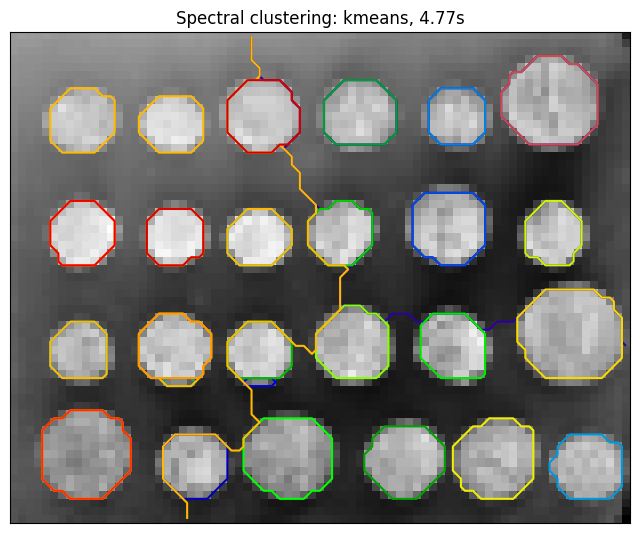

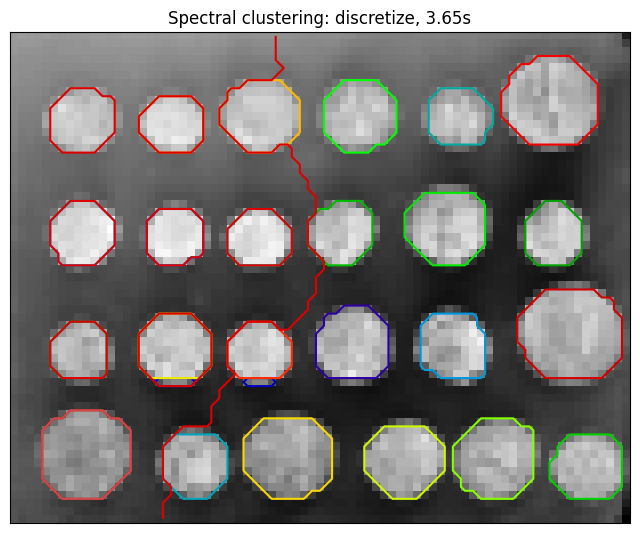

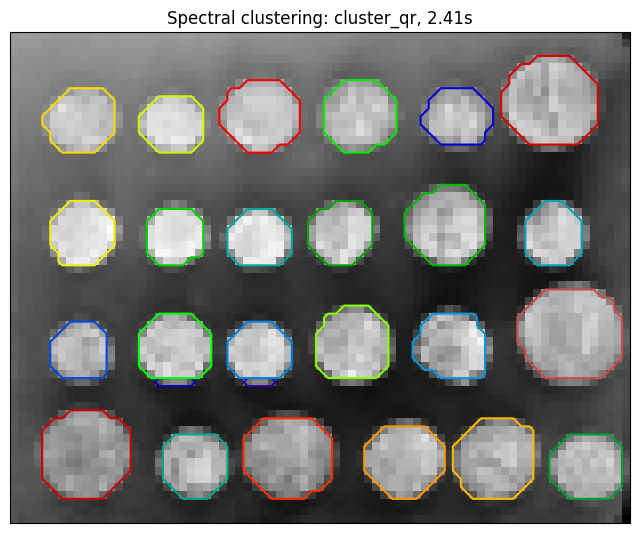

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.image import img_to_graph
from sklearn.cluster import spectral_clustering
from skimage.data import coins
from skimage.transform import rescale
from scipy.ndimage import gaussian_filter
import time

orig_coins = coins()

smoothened_coins = gaussian_filter(orig_coins, sigma=2)
rescaled_coins = rescale(smoothened_coins, 0.2, mode="reflect", anti_aliasing=False)


graph = img_to_graph(rescaled_coins)

beta = 10
eps = 1e-6
graph.data = np.exp(-beta * graph.data / graph.data.std()) + eps

n_regions = 26
n_regions_plus = 3

for assign_labels in ("kmeans", "discretize", "cluster_qr"):
    t0 = time.time()
    labels = spectral_clustering(
        graph,
        n_clusters=(n_regions + n_regions_plus),
        eigen_tol=1e-7,
        assign_labels=assign_labels,
        random_state=42,
    )
    t1 = time.time()

    labels = labels.reshape(rescaled_coins.shape)


    plt.figure(figsize=(8, 8))
    plt.imshow(rescaled_coins, cmap=plt.cm.gray)
    plt.xticks(())
    plt.yticks(())
    title = f"Spectral clustering: {assign_labels}, {t1 - t0:.2f}s"
    plt.title(title)
    print(title)


    for l in range(n_regions):
        color = plt.cm.nipy_spectral((l + 4) / float(n_regions + 4))
        plt.contour(labels == l, colors=[color])

plt.show()


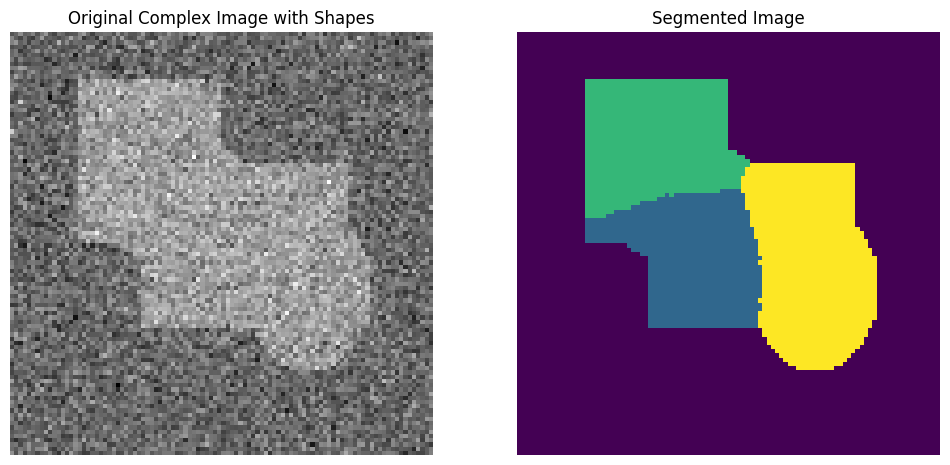

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.image import img_to_graph
from sklearn.cluster import spectral_clustering

l = 100
x, y = np.indices((l, l))

rect1 = (x > 10) & (x < 50) & (y > 15) & (y < 50)
rect2 = (x > 30) & (x < 70) & (y > 30) & (y < 80)
ellipse1 = ((x - 40) / 15) ** 2 + ((y - 40) / 20) ** 2 < 1
ellipse2 = ((x - 60) / 20) ** 2 + ((y - 70) / 15) ** 2 < 1

img = rect1 + rect2 + ellipse1 + ellipse2
mask = img.astype(bool)
img = img.astype(float)

img += 1 + 0.5 * np.random.randn(*img.shape)

graph = img_to_graph(img, mask=mask)
graph.data = np.exp(-graph.data / graph.data.std())

n_clusters = 6
labels = spectral_clustering(graph, n_clusters=n_clusters, eigen_solver='arpack')
label_im = -np.ones(mask.shape)
label_im[mask] = labels

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.title("Original Complex Image with Shapes")
plt.imshow(img, cmap="gray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title("Segmented Image")
plt.imshow(label_im, cmap="viridis")
plt.axis("off")

plt.show()
